# Notebook 01 — Exploration des données

## Objectif
Charger les fichiers CSV, fusionner les données d'entraînement et comprendre leur structure avant toute modélisation.

## Fichiers utilisés
- `data/X_train.csv` — variables explicatives des visites d'entraînement
- `data/y_train.csv` — variable cible (`target`)
- `data/X_test.csv` — visites pour lesquelles produire des prédictions

## Variables étudiées
Toutes les colonnes disponibles : données démographiques, génétiques, scores moteurs ON/OFF, doses, délais de prise.

## Résultat attendu
Compréhension complète de la structure des données, des valeurs manquantes, de la distribution de la cible et des risques de fuite entre patients.

## Notebook suivant
`02_baseline.ipynb` — construction d'un modèle de référence (DummyRegressor).

## 1. Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

## 2. Chargement des données

In [2]:
DATA_DIR = Path("../data")

X_train = pd.read_csv(DATA_DIR / "X_train.csv")
y_train = pd.read_csv(DATA_DIR / "y_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")

print(f"X_train : {X_train.shape}")
print(f"y_train : {y_train.shape}")
print(f"X_test  : {X_test.shape}")

X_train : (44590, 13)
y_train : (44590, 2)
X_test  : (11013, 13)


## 3. Vérifications d'intégrité

In [3]:
assert X_train["Index"].is_unique, "Index non unique dans X_train"
assert y_train["Index"].is_unique, "Index non unique dans y_train"
assert X_test["Index"].is_unique, "Index non unique dans X_test"

assert set(y_train.columns) == {"Index", "target"}, "Colonnes inattendues dans y_train"

print("Vérifications Index : OK")

Vérifications Index : OK


## 4. Fusion X_train et y_train

In [4]:
visits = X_train.merge(
    y_train,
    on="Index",
    how="inner",
    validate="one_to_one",
)

assert len(visits) == len(X_train), "Des lignes ont été perdues lors de la fusion"
assert len(visits) == len(y_train), "Des lignes ont été perdues lors de la fusion"
assert visits["target"].notna().all(), "Des valeurs manquantes dans target"

print(f"visits après fusion : {visits.shape}")
print("Fusion : OK — aucune ligne perdue")

visits après fusion : (44590, 14)
Fusion : OK — aucune ligne perdue


## 5. Structure des données

In [5]:
print("=== Colonnes de visits ===")
for col in visits.columns:
    print(f"  {col}: {visits[col].dtype}")

=== Colonnes de visits ===
  Index: int64
  patient_id: object
  cohort: object
  sexM: int64
  gene: object
  age_at_diagnosis: float64
  age: float64
  ledd: float64
  time_since_intake_on: float64
  time_since_intake_off: float64
  rater_id: object
  on: float64
  off: float64
  target: float64


In [6]:
visits.head()

,Index,patient_id,cohort,sexM,gene,age_at_diagnosis,age,ledd,time_since_intake_on,time_since_intake_off,rater_id,on,off,target
0,0,IPLP5212,A,0,LRRK2+,48.5,52.1,607.0,1.9,NaN,R36,7.0,NaN,34.7
1,1,IPLP5212,A,0,LRRK2+,48.5,53.0,666.0,1.9,17.6,R43,11.0,40.0,38.1
2,2,IPLP5212,A,0,LRRK2+,48.5,53.9,717.0,1.2,NaN,R43,6.0,NaN,41.6
3,3,IPLP5212,A,0,LRRK2+,48.5,54.8,770.0,1.5,NaN,R36,12.0,NaN,44.9
4,4,IPLP5212,A,0,LRRK2+,48.5,56.9,885.0,0.3,NaN,R36,26.0,NaN,52.0


In [7]:
visits.dtypes

Index                      int64
patient_id                object
cohort                    object
sexM                       int64
gene                      object
age_at_diagnosis         float64
age                      float64
ledd                     float64
time_since_intake_on     float64
time_since_intake_off    float64
rater_id                  object
on                       float64
off                      float64
target                   float64
dtype: object

## 6. Analyse des patients

In [8]:
n_patients_train = visits["patient_id"].nunique()
n_patients_test = X_test["patient_id"].nunique()

print(f"Nombre de patients (train) : {n_patients_train}")
print(f"Nombre de patients (test)  : {n_patients_test}")
print(f"Nombre de visites (train)  : {len(visits)}")
print(f"Nombre de visites (test)   : {len(X_test)}")
print(f"Visites moyennes par patient (train) : {len(visits) / n_patients_train:.2f}")

Nombre de patients (train) : 5576
Nombre de patients (test)  : 1395
Nombre de visites (train)  : 44590
Nombre de visites (test)   : 11013
Visites moyennes par patient (train) : 8.00


Distribution du nombre de visites par patient :
count    5576.000000
mean        7.996772
std         3.504563
min         4.000000
25%         4.000000
50%         7.000000
75%        12.000000
max        12.000000
dtype: float64


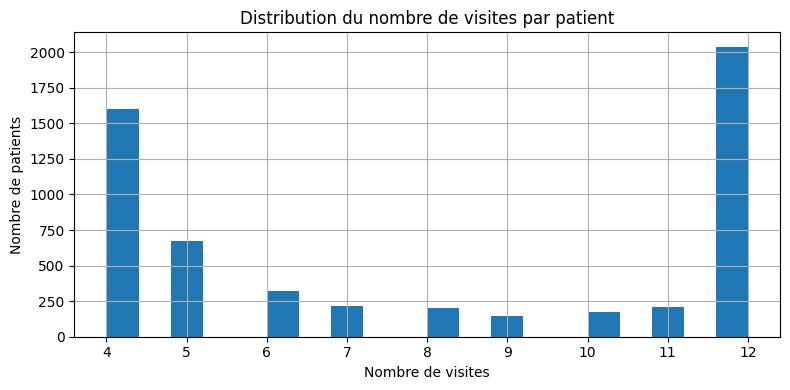

In [9]:
visits_per_patient = visits.groupby("patient_id").size()

print("Distribution du nombre de visites par patient :")
print(visits_per_patient.describe())

fig, ax = plt.subplots(figsize=(8, 4))
visits_per_patient.hist(bins=20, ax=ax)
ax.set_xlabel("Nombre de visites")
ax.set_ylabel("Nombre de patients")
ax.set_title("Distribution du nombre de visites par patient")
plt.tight_layout()
plt.show()

## 7. Valeurs manquantes

In [10]:
missing = (
    visits.isna()
    .sum()
    .rename("missing_count")
    .to_frame()
)
missing["missing_pct"] = (missing["missing_count"] / len(visits) * 100).round(2)
missing = missing[missing["missing_count"] > 0].sort_values("missing_pct", ascending=False)

print("Valeurs manquantes dans visits :")
display(missing)

Valeurs manquantes dans visits :


,missing_count,missing_pct
time_since_intake_off,35116,78.75
time_since_intake_on,20678,46.37
off,18913,42.42
ledd,16338,36.64
gene,14432,32.37
on,13220,29.65
age_at_diagnosis,2319,5.20


In [11]:
missing_test = (
    X_test.isna()
    .sum()
    .rename("missing_count")
    .to_frame()
)
missing_test["missing_pct"] = (missing_test["missing_count"] / len(X_test) * 100).round(2)
missing_test = missing_test[missing_test["missing_count"] > 0].sort_values("missing_pct", ascending=False)

print("Valeurs manquantes dans X_test :")
display(missing_test)

Valeurs manquantes dans X_test :


,missing_count,missing_pct
time_since_intake_off,8712,79.11
time_since_intake_on,5262,47.78
off,4494,40.81
ledd,4255,38.64
gene,3526,32.02
on,3439,31.23
age_at_diagnosis,511,4.64


## 8. Distribution de la cible (`target`)

In [12]:
print("Statistiques de target :")
print(visits["target"].describe())

Statistiques de target :
count    44590.000000
mean        37.471527
std         16.499679
min          0.000000
25%         25.600000
50%         37.300000
75%         49.300000
max        109.500000
Name: target, dtype: float64


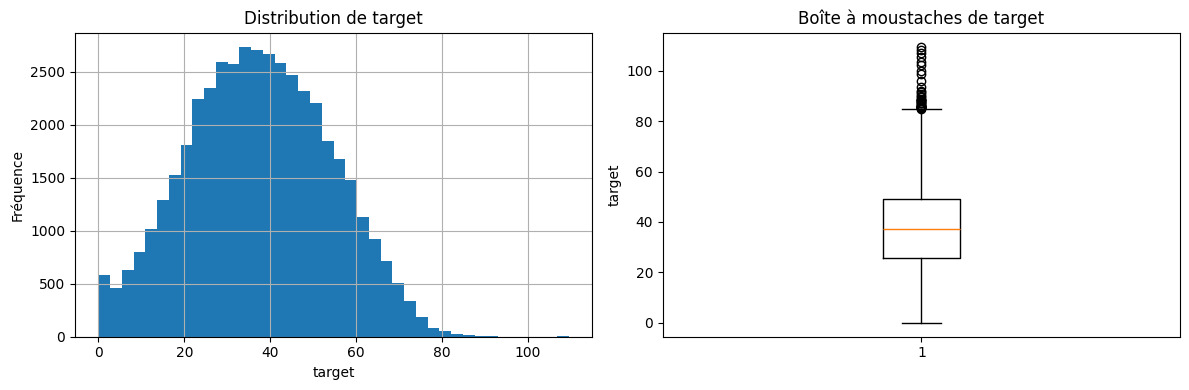

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

visits["target"].hist(bins=40, ax=axes[0])
axes[0].set_title("Distribution de target")
axes[0].set_xlabel("target")
axes[0].set_ylabel("Fréquence")

axes[1].boxplot(visits["target"].dropna())
axes[1].set_title("Boîte à moustaches de target")
axes[1].set_ylabel("target")

plt.tight_layout()
plt.show()

## 9. Analyse des variables catégorielles

In [14]:
for col in ["cohort", "gene", "rater_id"]:
    if col in visits.columns:
        n_unique = visits[col].nunique()
        print(f"\n{col} — {n_unique} valeurs distinctes :")
        print(visits[col].value_counts().head(20))


cohort — 2 valeurs distinctes :
cohort
A    39636
B     4954
Name: count, dtype: int64

gene — 4 valeurs distinctes :
gene
No Mutation    14250
LRRK2+          7588
GBA+            6357
OTHER+          1963
Name: count, dtype: int64

rater_id — 50 valeurs distinctes :
rater_id
R21    1046
R39     988
R40     979
R26     964
R34     957
R08     956
R31     955
R13     955
R29     953
R46     951
R45     951
R23     940
R36     940
R37     936
R12     935
R18     926
R15     922
R48     918
R25     915
R10     909
Name: count, dtype: int64


## 10. Relations entre les variables et `target`

In [15]:
numeric_cols = ["age", "age_at_diagnosis", "ledd", "time_since_intake_on",
                "time_since_intake_off", "on", "off"]

corr = visits[numeric_cols + ["target"]].corr()["target"].drop("target").sort_values(key=abs, ascending=False)

print("Corrélation de Pearson avec target :")
print(corr.round(4))

Corrélation de Pearson avec target :
off                      0.8712
on                       0.6687
age                      0.3098
ledd                     0.2981
age_at_diagnosis         0.1331
time_since_intake_off    0.0083
time_since_intake_on     0.0002
Name: target, dtype: float64


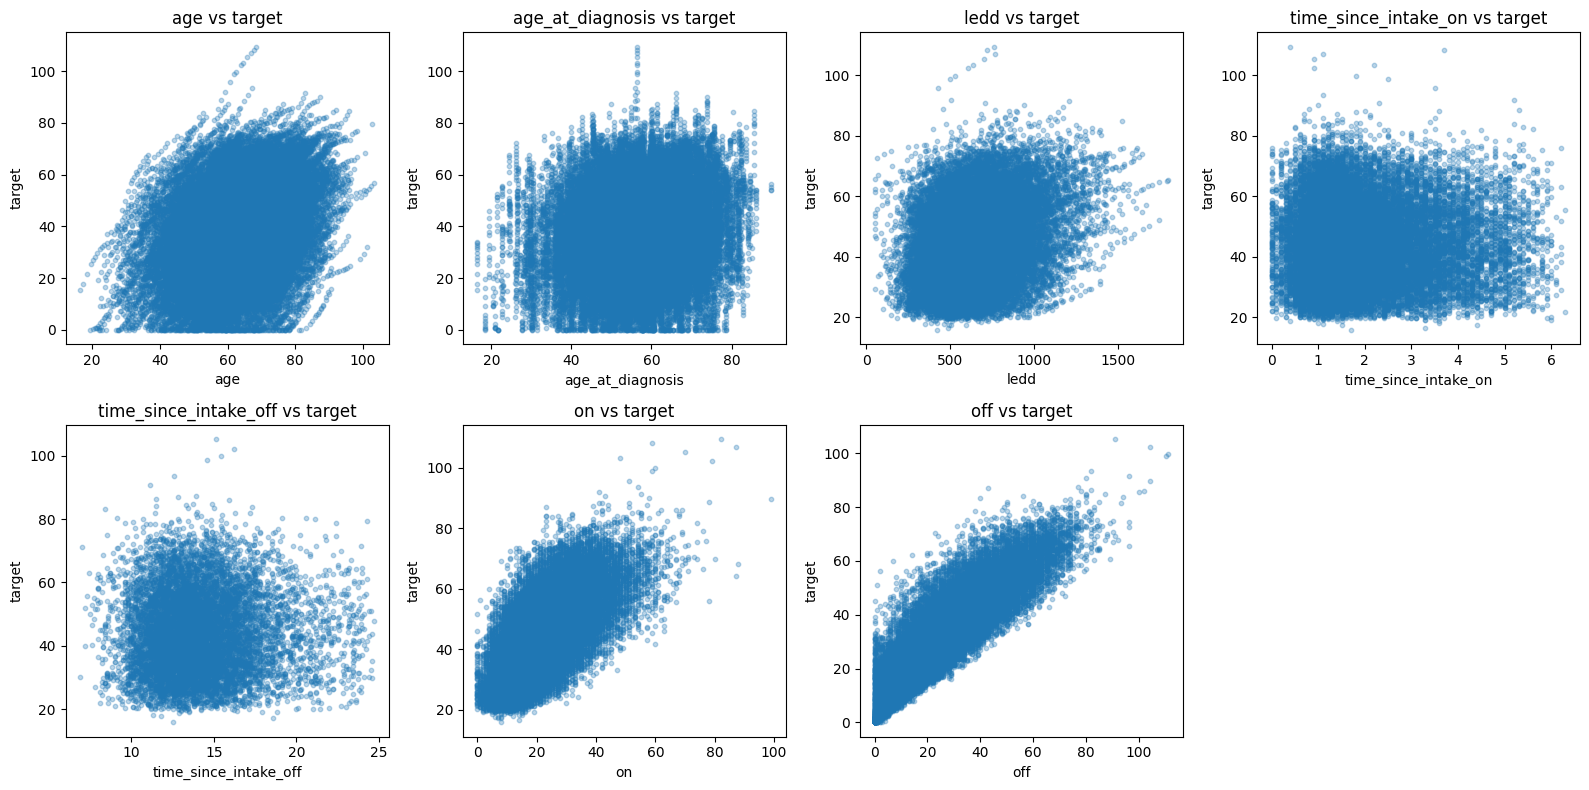

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    subset = visits[[col, "target"]].dropna()
    axes[i].scatter(subset[col], subset["target"], alpha=0.3, s=10)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("target")
    axes[i].set_title(f"{col} vs target")

# Désactiver le dernier axes si impair
if len(numeric_cols) < len(axes):
    axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

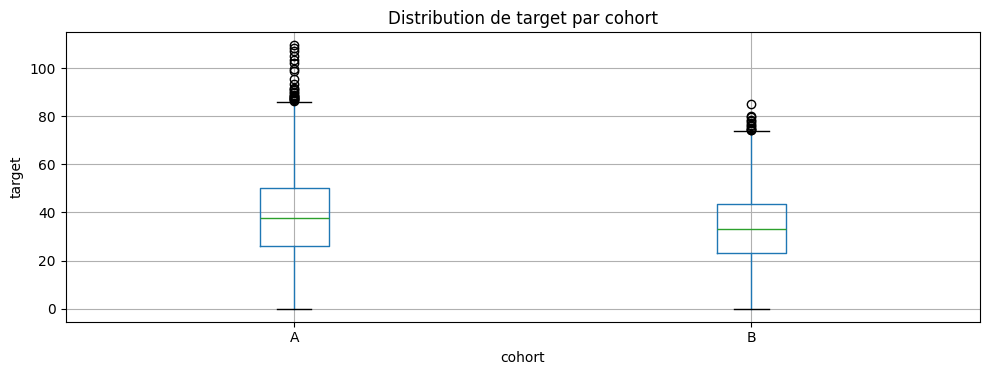

In [17]:
if "cohort" in visits.columns:
    fig, ax = plt.subplots(figsize=(10, 4))
    visits.boxplot(column="target", by="cohort", ax=ax)
    ax.set_title("Distribution de target par cohort")
    ax.set_xlabel("cohort")
    ax.set_ylabel("target")
    plt.suptitle("")
    plt.tight_layout()
    plt.show()

## 11. Risques de fuite de données

### Problème principal : plusieurs visites par patient

Chaque patient possède plusieurs visites. Une validation aléatoire par ligne (par exemple avec `KFold` standard) peut placer certaines visites d'un même patient à la fois dans l'ensemble d'entraînement et dans l'ensemble de validation.

Dans ce cas, le modèle "voit" indirectement des informations sur un patient qu'il est censé ne pas connaître. Cela conduit à une **surestimation des performances locales** et à une **dégradation sur le jeu de test Kaggle**.

**Solution** : utiliser `GroupKFold(n_splits=5)` avec `groups = visits["patient_id"]` pour s'assurer qu'un patient n'apparaît jamais dans les deux parties d'un fold.

### Variables à exclure

- `Index` : identifiant de ligne, aucune valeur prédictive
- `patient_id` : identifiant patient, risque de mémorisation
- `target` : la variable cible ne doit jamais apparaître dans les features

### Variables à traiter avec prudence

- `rater_id` : l'évaluateur peut introduire un biais artificiel si certains évaluateurs n'évaluent qu'un sous-ensemble de patients
- `off` : si la mesure OFF est déjà très proche de `target`, son inclusion peut créer une fuite subtile

In [18]:
# Vérification : les patients train et test se chevauchent-ils ?
patients_train = set(visits["patient_id"].unique())
patients_test = set(X_test["patient_id"].unique())

overlap = patients_train & patients_test
print(f"Patients présents uniquement dans train : {len(patients_train - patients_test)}")
print(f"Patients présents uniquement dans test  : {len(patients_test - patients_train)}")
print(f"Patients présents dans train ET test    : {len(overlap)}")

Patients présents uniquement dans train : 5576
Patients présents uniquement dans test  : 1395
Patients présents dans train ET test    : 0


## 12. Conclusion

Les données représentent des visites médicales pour des patients atteints de la maladie de Parkinson. Chaque ligne est une visite ; plusieurs visites existent par patient.

**Points clés à retenir :**

1. **Valeurs manquantes** : plusieurs colonnes (`on`, `off`, `ledd`, `time_since_intake_on`, `time_since_intake_off`) contiennent des valeurs manquantes. Ces absences peuvent être informatives (le patient n'a pas reçu de traitement, par exemple) et ne doivent pas être supprimées sans réflexion.

2. **Variables catégorielles** : `cohort`, `gene` et `rater_id` nécessitent un encodage adapté. Elles ne peuvent pas être utilisées directement par Ridge ou HGBR sans traitement préalable.

3. **Fuite entre patients** : la validation doit impérativement être groupée par `patient_id` avec `GroupKFold`. Une validation aléatoire produirait des métriques trop optimistes.

4. **Distribution de `target`** : la cible est continue. Une régression est appropriée. La distribution est à inspecter pour déceler d'éventuels outliers.

5. **Variable `off`** : cette colonne est le score moteur OFF observé, proche conceptuellement de `target`. Elle peut apporter beaucoup, mais doit être utilisée avec prudence.

**Prochaine étape** : `02_baseline.ipynb` — construire un `DummyRegressor(strategy="mean")` comme référence.